# 06 · Validation

Step 6 of the QSAR workflow, the parts the per-model notebooks leave out. All three read files
written by `scripts/validate.py`; nothing is refitted here.

1. **The comparison table** the proposal asks for, with every measure it names: AUC, MCC, log
   loss, Brier and calibration error.
2. **Y-randomization** — the check that the pipeline is not leaking.
3. **Cross-validation** — error bars, so a gap between two models can be called real or not.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

metrics = pd.read_csv(PROC / "validation_metrics.csv")
yrand   = pd.read_csv(PROC / "validation_yrandomization.csv")
cv      = pd.read_csv(PROC / "validation_cv.csv")
baseline = pd.read_csv(PROC / "baseline_rf.csv")

ORDER = ["Model 1 logistic", "Model 2 censored", "Model 3 GP"]
COLOUR = {"Model 1 logistic": "#2a78d6", "Model 2 censored": "#d68a2a",
          "Model 3 GP": "#5a9e5a", "RF baseline": "#999999"}

## 1. The comparison table

One row per fitted model on its held-out test set. ARD and Gaussian priors differ by less than
0.01 everywhere, so only ARD is shown.

**ECE** (expected calibration error) is the mean gap between the probability a model announces
and the frequency it actually achieves. 0.02 means that when the model says 70%, the truth is
within about two points of that. It is the number that answers the proposal's question *are
the probabilities honest*; AUC cannot, because it only looks at ranking.

In [2]:
tab = (metrics[metrics["variant"].str.startswith(("ard", "tanimoto"))]
       .pivot_table(index="model", columns="split",
                    values=["AUC", "MCC", "log loss", "ECE"])
       .reindex(ORDER))
tab.round(3)

AUC                            ECE                \
split            cluster   hard random scaffold cluster   hard random   
model                                                                   
Model 1 logistic   0.856    NaN  0.874      NaN   0.045    NaN  0.032   
Model 2 censored   0.847    NaN  0.857      NaN   0.057    NaN  0.048   
Model 3 GP         0.865  0.858  0.879    0.873   0.058  0.056  0.072   

                              MCC                       log loss         \
split            scaffold cluster  hard random scaffold  cluster   hard   
model                                                                     
Model 1 logistic      NaN   0.548   NaN  0.575      NaN    0.478    NaN   
Model 2 censored      NaN   0.518   NaN  0.540      NaN    0.492    NaN   
Model 3 GP          0.077   0.565  0.54  0.595    0.586    0.468  0.482   

                                  
split            random scaffold  
model                             
Model 1 logistic  0.447      NaN  
Model 2 censored  0.479      NaN  
Model 3 GP        0.455    0.465

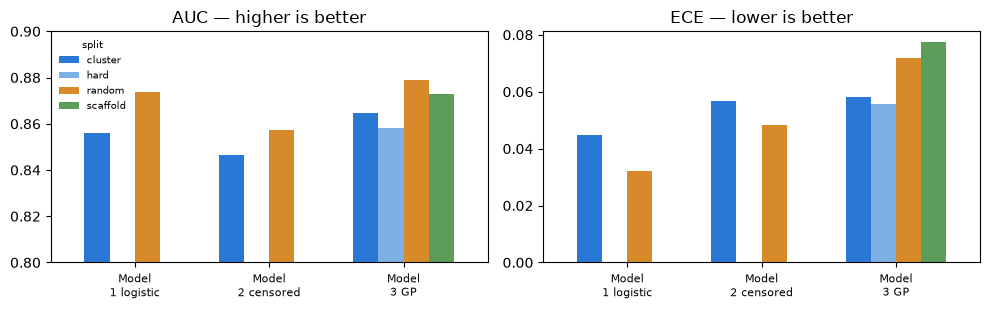

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (col, better) in zip(axes, [("AUC", "higher is better"), ("ECE", "lower is better")]):
    sub = metrics[metrics["variant"].str.startswith(("ard", "tanimoto"))]
    sub = sub.pivot_table(index="model", columns="split", values=col).reindex(ORDER)
    sub.plot.bar(ax=ax, width=0.75, legend=(col == "AUC"),
                 color=["#2a78d6", "#7fb0e5", "#d68a2a", "#5a9e5a"])
    ax.set_title(f"{col} — {better}"); ax.set_xlabel("")
    ax.set_xticklabels([t.get_text().replace(" ", "\n", 1) for t in ax.get_xticklabels()],
                       rotation=0, fontsize=8)
    if col == "AUC":
        ax.set_ylim(0.8, 0.9); ax.legend(title="split", fontsize=7, title_fontsize=7, frameon=False)
plt.tight_layout(); plt.show()

### What the table says

**The best-ranking model is the worst-calibrated one.** Model 3 wins on AUC and loses on ECE,
by a factor of three. The Laplace approximation for GP classification is known to understate
the magnitude of the latent function, and this is that showing up as a number: the GP's
probabilities are too close to 0.5 to be taken at face value.

That matters here more than the AUC does. The proposal's goal is a *calibrated* probability a
chemist can act on — "a 70% chance this flies" has to mean 70%. On that test Model 1 wins and
Model 3 comes last, which is the reverse of the AUC ranking.

## 2. Y-randomization

Shuffle the training labels, refit, score against the real test labels, 25 times per split. A
model that scores well on scrambled labels is reading something other than chemistry.

The shuffled AUCs scatter widely (sd ≈ 0.09) because 50 free coefficients fitted to noise can
land on a direction that happens to correlate with the truth. That is exactly why the check is
worth running: the spread, not just the mean, is what the real score has to clear.

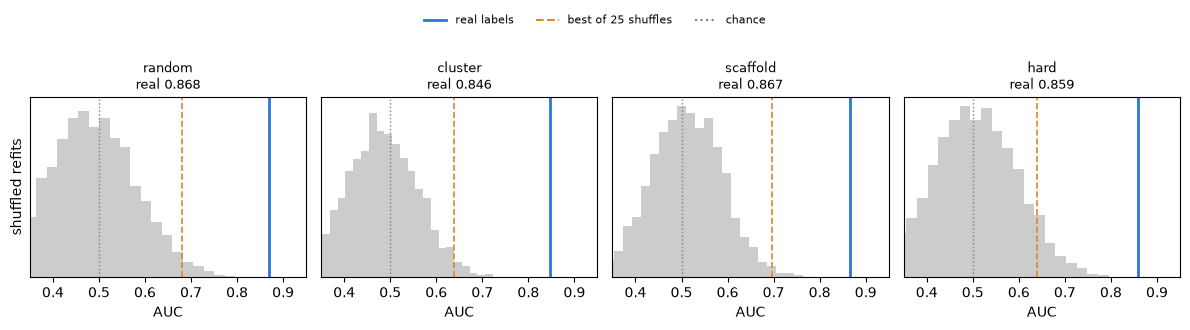

,split,real AUC,shuffled mean,shuffled sd,shuffled max,z,reps
0,random,0.868,0.485,0.095,0.680,4.019,25
1,cluster,0.846,0.479,0.078,0.638,4.726,25
2,scaffold,0.867,0.507,0.080,0.697,4.499,25
3,hard,0.859,0.502,0.094,0.639,3.792,25


In [4]:
fig, axes = plt.subplots(1, len(yrand), figsize=(3.0 * len(yrand), 2.9), sharey=True)
rng = np.random.default_rng(0)
for ax, (_, r) in zip(np.atleast_1d(axes), yrand.iterrows()):
    draws = rng.normal(r["shuffled mean"], r["shuffled sd"], 4000)
    ax.hist(draws, bins=30, color="#cccccc", edgecolor="none")
    ax.axvline(0.5, color="0.5", ls=":", lw=1)
    ax.axvline(r["shuffled max"], color="#d68a2a", ls="--", lw=1.2)
    ax.axvline(r["real AUC"], color="#2a78d6", lw=2)
    ax.set_title(f"{r['split']}\nreal {r['real AUC']:.3f}", fontsize=9)
    ax.set_xlim(0.35, 0.95); ax.set_yticks([]); ax.set_xlabel("AUC")
axes[0].set_ylabel("shuffled refits")
fig.legend(handles=[plt.Line2D([], [], color="#2a78d6", lw=2, label="real labels"),
                    plt.Line2D([], [], color="#d68a2a", ls="--", label="best of 25 shuffles"),
                    plt.Line2D([], [], color="0.5", ls=":", label="chance")],
           loc="upper center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.14))
plt.tight_layout(); plt.show()

yrand.round(3)

**Passed.** On every split the shuffled fits average about 0.49 — chance — and the luckiest of
25 reaches 0.70 at most, while the real model scores 0.85–0.87. The gap is four to five
standard deviations. Whatever the model has learnt, it is in the labels, not in the plumbing.

## 3. Cross-validation

Five folds inside each training set, with whole scaffolds and clusters kept together, so a fold
is as honest as the outer test set. This is the only place in the project that produces a
spread rather than a single number, and the spread is what decides whether a gap is real.

Model 3 is absent on purpose: one GP fit takes about eight minutes, so twenty of them would
cost hours to answer a question the two fast models already answer.

In [5]:
FEATURES = "morgan+chem"          # the set the screen chose; "chem" is also in the file
sub = cv[cv["features"] == FEATURES]
agg = (sub.groupby(["split", "model"])[["AUC", "MCC", "log loss", "ECE"]]
          .agg(["mean", "std"]).round(3))
agg

AUC           MCC        log loss           ECE  \
                           mean    std   mean    std     mean    std   mean   
split   model                                                                 
cluster Model 1 logistic  0.871  0.005  0.581  0.014    0.473  0.017  0.052   
        Model 2 censored  0.867  0.006  0.565  0.014    0.467  0.011  0.042   
        RF baseline       0.878  0.007  0.582  0.027    0.479  0.003  0.102   
random  Model 1 logistic  0.876  0.010  0.581  0.031    0.455  0.025  0.050   
        Model 2 censored  0.871  0.005  0.568  0.017    0.456  0.009  0.041   
        RF baseline       0.878  0.004  0.582  0.011    0.479  0.005  0.106   

                                 
                            std  
split   model                    
cluster Model 1 logistic  0.006  
        Model 2 censored  0.009  
        RF baseline       0.014  
random  Model 1 logistic  0.016  
        Model 2 censored  0.012  
        RF baseline       0.003

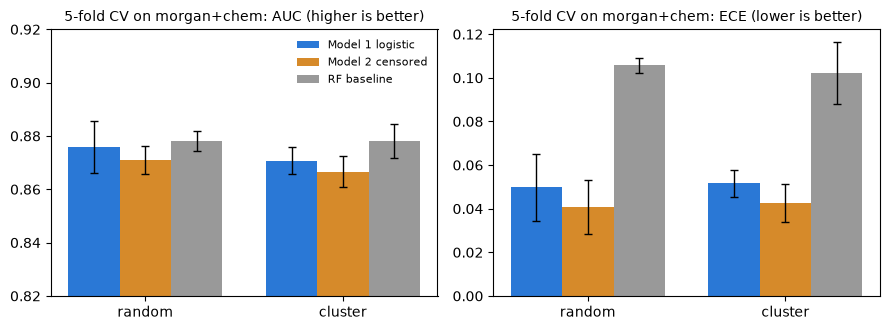

In [6]:
models = ["Model 1 logistic", "Model 2 censored", "RF baseline"]
splits = list(sub["split"].unique())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))

for ax, col, better in [(axes[0], "AUC", "higher"), (axes[1], "ECE", "lower")]:
    w = 0.26
    for j, m in enumerate(models):
        s = sub[sub["model"] == m].groupby("split")[col].agg(["mean", "std"]).reindex(splits)
        ax.bar(np.arange(len(splits)) + (j - 1) * w, s["mean"], w, yerr=s["std"],
               capsize=3, color=COLOUR[m], label=m, error_kw={"lw": 1})
    ax.set_xticks(range(len(splits))); ax.set_xticklabels(splits)
    ax.set_title(f"5-fold CV on {FEATURES}: {col} ({better} is better)", fontsize=10)
    if col == "AUC":
        ax.set_ylim(0.82, 0.92); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

In [7]:
# Is either lead bigger than fold-to-fold noise? Pair within a fold, which removes the
# fold difficulty both models share, then look at the sign as well as the size.
pairs = sub.pivot_table(index=["split", "fold"], columns="model", values=["AUC", "ECE"])
for other in ["RF baseline", "Model 2 censored"]:
    for col in ["AUC", "ECE"]:
        d = pairs[col]["Model 1 logistic"] - pairs[col][other]
        wins = int((d > 0).sum()) if col == "AUC" else int((d < 0).sum())
        print(f"Model 1 minus {other:17s} {col:4s} {d.mean():+.3f} +- {d.std():.3f}"
              f"   Model 1 better in {wins}/{len(d)} folds")

Model 1 minus RF baseline       AUC  -0.005 +- 0.009   Model 1 better in 3/10 folds
Model 1 minus RF baseline       ECE  -0.053 +- 0.015   Model 1 better in 10/10 folds
Model 1 minus Model 2 censored  AUC  +0.005 +- 0.004   Model 1 better in 9/10 folds
Model 1 minus Model 2 censored  ECE  +0.009 +- 0.017   Model 1 better in 2/10 folds


### What cross-validation settles

**It overturns the single-split reading on AUC.** On one split Model 1 scored 0.891 against the
forest's 0.885 and looked ahead. Across ten folds the difference is −0.005 ± 0.009 with the
forest ahead more often than not. The spread is twice the gap, so on ranking these two are the
same model and the single split was noise. This is the whole reason for running folds.

**Calibration is not noise.** Model 1 has the lower calibration error in 10 folds out of 10,
by roughly half. And Model 2 — slightly behind on ranking — is the best calibrated of the three:
modelling the peak area and deriving a probability from it beats modelling the yes/no answer.

So the honest summary is not "the Bayesian models predict better". It is: *they predict about as
well and they know what they know*. For a screen deciding which compounds to run, the second
property is the one worth having.

**A caveat on feature width.** The same comparison on the 50 chemistry features (all four
splits, also in `validation_cv.csv`) puts Model 1 ahead on both counts, 20 folds of 20 on AUC.
A linear model does relatively better where the features are few and already meaningful; the
forest catches up where there are 2,048 raw bits and interactions between them to find.

**The splits agree with each other.** Random, cluster, scaffold and hard land within 0.01 AUC.
That is a statement about the library rather than the models: with 7,067 clusters among 11,353
compounds and most of them singletons, holding out "new chemistry" is barely harder than holding
out at random. A model trained here should be expected to generalise — but it also means this
dataset cannot demonstrate an applicability domain, having no genuinely out-of-domain corner to
fail on.